<a href="https://colab.research.google.com/github/btuka0309-ux/ml-w4/blob/main/W4_%D0%91%D0%B0%D1%82%D0%BC%D3%A9%D0%BD%D1%85_%D0%A2%D1%83%D0%BB%D0%B3%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**А1. Регресс ба ангиллын ялгаа**

Регресс нь тасралтгүй тоон утга таамагладаг (жишээ нь байрны үнэ хэд вэ), ангилал нь урьдчилан
тодорхойлсон ангийн аль нэгийг таамагладаг (жишээ нь энэ имэйл спам уу, үгүй юу). Гол ялгаа нь
гаралтын төрөл: регрессийн гаралт тоо, ангиллын гаралт ангийн нэр эсвэл магадлал.
- (a) Ирэх сарын борлуулалтын дүн: **регресс**, учир нь гаралт нь тасралтгүй тоо.
- (b) Харилцагч дараагийн сард гарах эсэх: **ангилал**, учир нь гаралт нь 0/1 (гарна/гарахгүй).
- (c) Зээлийн хүсэлтийг зөвшөөрөх эсэх: **ангилал**, учир нь гаралт нь зөвшөөрөх/татгалзах.


**А2. Шугаман регрессийг 0/1 ангилалд хэрэглэх асуудал**
1. **Гаралт нь 0–1-ээс гадуур гарна.** Шугаман загвар нь ŷ = w·x гэж тооцдог тул −0.4 эсвэл 1.7 гэх мэт
   утга гарч магадлал гэж тайлбарлах боломжгүй. Логистик регресс нь шугаман хэсгийг сигмоидоор
   дамжуулж гаралтыг үргэлж (0, 1) завсарт байлгадаг.
2. **Алдагдал ба шулуун нь ангилалд тохирдоггүй.** Хол байрлах нэг цэг (жишээ нь маш өндөр орлоготой
   хүн) шулууныг татаж гажуулах ба MSE нь 0/1 тэмдэглэгээнд ангилах чадварыг шууд хэмждэггүй.
   Логистик регресс нь log loss-оор магадлалын үнэлгээг шууд оновчилдог бөгөөд хол цэг нь
   шийдвэрийн хилийг хэт хөдөлгөхгүй.

**А3. Сигмоид функц**

σ(z) = 1 / (1 + e^−z)
- (a) σ(0) = 1 / (1 + 1) = **0.5**
- (b) z → −∞ үед e^−z → ∞ тул σ(z) → **0**
- (c) z → +∞ үед e^−z → 0 тул σ(z) → **1**

Гаралт нь үргэлж (0, 1) завсарт байж, z өсөх тусам жигд нэмэгддэг тул магадлал гаргахад тохиромжтой.
σ(−z) = 1 − σ(z) гэдэг нь тэгш хэмийг заана. Хэрэв P(default) = σ(z) бол P(сайн зээл) = 1 − σ(z) = σ(−z)
байна. Өөрөөр хэлбэл z-ийн тэмдгийг эргүүлэхэд хоёр ангийн магадлал солигдох ба нийлбэр нь үргэлж 1 байна.


### **A4 Log loss ба MSE**
Log loss = −[y·ln(p) + (1−y)·ln(1−p)], MSE = (y − p)². Сигмоидтой хамт MSE ашиглавал алдагдлын
гадарга гүдгэр биш болж, градиент нь σ'(z) = σ(z)(1−σ(z)) үржвэртэй болдог. Загвар хэт итгэлтэй
(p ≈ 0 эсвэл 1) боловч буруу байх үед σ'(z) ≈ 0 тул градиент тэг рүү ойртож, сургалт удааширдаг.
Log loss-д энэ үржвэр хасагдаж градиент нь (p − y)·x гэсэн энгийн хэлбэртэй болдог, мөн гүдгэр.

**«Итгэлтэй буруу таамаглал» жишээ:** цаг агаарын мэдээ "маргааш 99% бороо орно" гэсэн боловч бороо
ороогүй (y = 0, p = 0.99). Log loss = −ln(1 − 0.99) = ln(100) ≈ **4.605**, харин MSE = 0.99² ≈ 0.98.
Харин "51% бороо орно" гэж таамагласан бол log loss = −ln(0.49) ≈ 0.713 л байна. Log loss нь
хэт итгэлтэй алдааг маш хүнд торгодог бол MSE хангалттай торгодоггүй.


**А5. Precision ба recall**
- **Precision = TP / (TP + FP)**: "positive" гэж зарласнаас хэд нь үнэхээр positive вэ.
- **Recall = TP / (TP + FN)**: бодит positive-уудын хэдийг нь олсон бэ.

Аль нь гол вэ гэдэг нь аль алдаа нь илүү үнэтэй байхаас хамаарна:
- (a) **Спам шүүлт: precision.** Чухал имэйлийг спамд буруугаар оруулах (FP) нь хэрэглэгчид хамгийн их хохирол учруулна.
- (b) **Зээлийн default: recall.** Алдсан default (FN) нь банкинд хамгийн үнэтэй (энэ даалгаварт 10 нэгж, буруу дохиолол 1 нэгж).
- (c) **Халдварт өвчний шинжилгээ: recall.** Өвчтэй хүнийг алдах (FN) нь халдвар тархаж, эмчлэлт хоцорч аюултай,
  харин эрүүл хүнийг буруу сэжиглэх (FP) нь давтан шинжилгээгээр засагдана.

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y = make_classification(
    n_samples=4000, n_features=8, n_informative=5,
    n_redundant=1, weights=[0.94, 0.06],
    flip_y=0.03, class_sep=1.1, random_state=4)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)
print(X.shape, X_train.shape, X_test.shape)
print(y_test.sum(), "эерэг /", len(y_test))

(4000, 8) (3000, 8) (1000, 8)
73 эерэг / 1000


In [2]:
def sigmoid(z):
    z = np.clip(z, -500, 500)      # exp(-z) overflow болохоос сэргийлнэ
    return 1 / (1 + np.exp(-z))

z = np.array([-1000, -2, 0, 2, 1000])
print(np.round(sigmoid(z), 4))     # [0. 0.1192 0.5 0.8808 1.]

[0.     0.1192 0.5    0.8808 1.    ]


float64 нь ойролцоогоор e^709-өөс том тоог хадгалж чадахгүй. z = −1000 үед np.exp(1000) нь inf болж, overflow warning гарна.
Clip хийснээр exp(500) нь том ч гэсэн хязгаарт багтана. Үр дүн нь ≈ 7·10⁻²¹⁸ буюу 0-д маш ойр байна.
Сигмоид 0 болж "унадаггүй", харин 0-д асимптотоор ойртдог. Магадлал нь хэзээ ч яг 0 эсвэл 1 болдоггүй.

In [3]:
def log_loss_manual(y, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)   # log(0) = -inf болохоос сэргийлнэ
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

print(log_loss_manual(np.array([1]), np.array([0.9])))  # 0.1054
print(log_loss_manual(np.array([1]), np.array([0.1])))  # 2.3026
print(log_loss_manual(np.array([0]), np.array([0.9])))  # 2.3026

0.10536051565782628
2.3025850929940455
2.302585092994046


Яагаад 2.3026 гарах вэ:

(y=1, p=0.1) үед алдагдал нь −ln(0.1) = ln(10) ≈ 2.3026.
(y=0, p=0.9) үед алдагдал нь −ln(1−0.9) = −ln(0.1) = ln(10), өөрөөр хэлбэл ижил.
Хоёулаа "90% итгэлтэй, гэхдээ буруу" тохиолдол учраас ижил торгууль авна. Зөв таамаглал (p=0.9) нь зөвхөн −ln(0.9) = 0.1054 торгууль авна.

Эхний алдагдал: 0.6931
Сүүлийн алдагдал: 0.1625


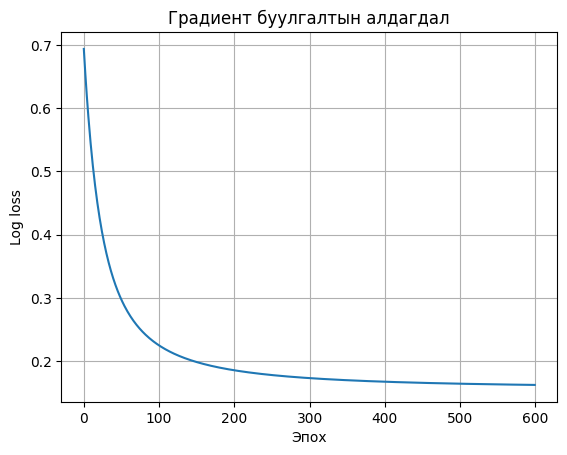

Тестийн AUC: 0.8766


In [4]:
# a) Scaler: зөвхөн train дээр fit, test дээр transform (leakage-гүй)
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
Xs_train = (X_train - mean) / std
Xs_test = (X_test - mean) / std

# b) Bias багана нэмнэ
N = Xs_train.shape[0]
Xb = np.c_[np.ones(N), Xs_train]
Xb_test = np.c_[np.ones(Xs_test.shape[0]), Xs_test]

# c) Жинг тэгээс эхлүүлнэ
w = np.zeros(Xb.shape[1])

# e) lr = 0.1, 600 эпох
lr = 0.1
epochs = 600
losses = []

for epoch in range(epochs):
    p = sigmoid(Xb @ w)
    losses.append(log_loss_manual(y_train, p))   # эпох бүрийн алдагдал
    grad = Xb.T @ (p - y_train) / N              # d) градиент
    w = w - lr * grad                            # жин шинэчлэх

print("Эхний алдагдал:", round(losses[0], 4))    # ≈ 0.6931
print("Сүүлийн алдагдал:", round(losses[-1], 4)) # ≈ 0.1625

# f) Алдагдлын график
plt.plot(range(epochs), losses)
plt.xlabel("Эпох")
plt.ylabel("Log loss")
plt.title("Градиент буулгалтын алдагдал")
plt.grid(True)
plt.show()

# g) Тестийн AUC (sklearn ашиглахгүй, гараар)
p_test = sigmoid(Xb_test @ w)

def auc_manual(y, s):
    pos = s[y == 1]
    neg = s[y == 0]
    # Эерэг бүрийн оноо нь сөрөг бүрийнхээс их байх магадлал
    greater = (pos[:, None] > neg[None, :]).mean()
    ties = (pos[:, None] == neg[None, :]).mean()
    return greater + 0.5 * ties

print("Тестийн AUC:", round(auc_manual(y_test, p_test), 4))  # ≈ 0.877

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import log_loss, roc_auc_score

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1.0, max_iter=1000),
)
model.fit(X_train, y_train)
p = model.predict_proba(X_test)[:, 1]    # P(default)

print("Тестийн log loss:", round(log_loss(y_test, p), 4))   # ≈ 0.149
print("Тестийн ROC-AUC:", round(roc_auc_score(y_test, p), 4))  # ≈ 0.871

Тестийн log loss: 0.1489
Тестийн ROC-AUC: 0.871


   Босго   TN  FP  FN  TP  Accuracy  Precision  Recall     F1
0   0.50  924   3  39  34     0.958      0.919   0.466  0.618
1   0.35  918   9  29  44     0.962      0.830   0.603  0.698
2   0.25  907  20  26  47     0.954      0.701   0.644  0.671
3   0.15  872  55  21  52     0.924      0.486   0.712  0.578


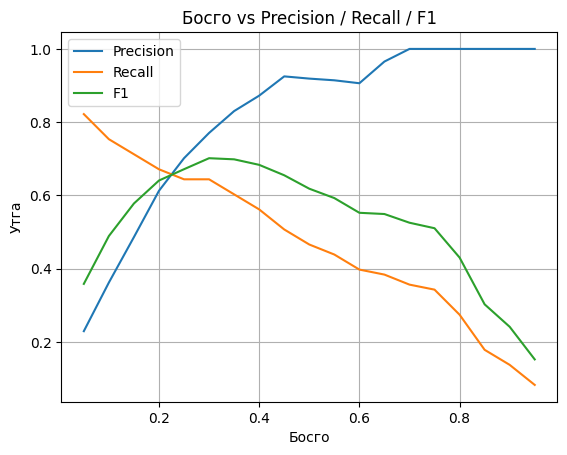

In [6]:
from sklearn.metrics import confusion_matrix

def metrics_at(th):
    pred = (p >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    acc = (tp + tn) / (tp + tn + fp + fn)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn)
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0
    return tn, fp, fn, tp, acc, prec, rec, f1

rows = []
for th in [0.50, 0.35, 0.25, 0.15]:
    rows.append((th, *metrics_at(th)))
table = pd.DataFrame(rows, columns=["Босго","TN","FP","FN","TP","Accuracy","Precision","Recall","F1"]).round(3)
print(table)

# a) График: босго vs precision, recall, F1
ths = np.arange(0.05, 0.96, 0.05)
prec_l, rec_l, f1_l = [], [], []
for th in ths:
    _, _, _, _, _, pr, rc, f = metrics_at(th)
    prec_l.append(pr); rec_l.append(rc); f1_l.append(f)

plt.plot(ths, prec_l, label="Precision")
plt.plot(ths, rec_l, label="Recall")
plt.plot(ths, f1_l, label="F1")
plt.xlabel("Босго"); plt.ylabel("Утга"); plt.legend(); plt.grid(True)
plt.title("Босго vs Precision / Recall / F1")
plt.show()

### В1

**Тестийн үр дүн:** log loss = 0.1489, ROC-AUC = 0.871.

**Б3-ын гар аргын AUC (0.877) ба энд гарсан AUC (0.871) яагаад ижил түвшинд байна вэ:**
Хоёулаа ижил загвар буюу логистик регресс бөгөөд log loss-ийг минимумчилдэг. Ялгаа нь зөвхөн
оновчлолын арга болон регуляризац. Б3-д би градиент буулгалтыг 600 эпох ажиллуулсан, харин sklearn
L-BFGS ашигладаг бөгөөд C=1.0 гэсэн L2 регуляризацтай. Тиймээс жингүүд бага зэрэг өөр боловч
AUC нь зөвхөн магадлалуудын **эрэмбээс** хамаардаг (эерэг жишээ сөрөг жишээнээс өндөр оноо авах
магадлал). Эрэмбэ бараг ижил байгаа тул AUC 0.877 ба 0.871 ойролцоо гарсан.

**predict_proba ба predict-ийн ялгаа:**
- `predict_proba(X)[:, 1]` нь P(default) магадлал (0-ээс 1) буцаана.
- `predict(X)` нь тэр магадлалыг **0.5 босгоор** таслаад 0/1 анги буцаана.

Тэнцвэргүй датад (default 7.3%) 0.5 босго тохиромжгүй байж болно. Иймд В2-т
`predict`-ийн оронд `predict_proba`-г авч босгыг өөрөө өөрчилж үнэлсэн.

### В2
**Хүснэгтээс харахад:** босго 0.50-аас 0.15 болж буурахад recall 0.466 → 0.712 өссөн,
харин precision 0.919 → 0.486 буурсан. F1 нь 0.35 босгон дээр хамгийн өндөр (0.698).

**Яагаад recall өсөж, precision буурах вэ:**
Босгыг буулгахад загвар P(default) ≥ босго гэсэн илүү олон хүнийг "default" гэж зарлана.
- Бодит default-уудаас илүү олныг барих тул FN буурч, TP өсөж, recall = TP/(TP+FN) өснө.
- Гэхдээ сайн зээлтэй хүмүүсийг буруугаар default гэж зарлах нь бас нэмэгдэнэ (FP: 3 → 55).
  Зарласан бүх хүний дундах зөв хувь буюу precision = TP/(TP+FP) буурна.

Иймд recall ба precision хоорондоо **солилцоотой (trade-off)**: нэгийг нь нэмэхийн тулд нөгөөгөөс нь алдана.

**Accuracy-ийн тухай:** 0.50 босгон дээр accuracy 95.8% боловч default-ын ердөө 46.6%-ийг барьж байна.
Датад default ердөө 7.3% тул бүгдийг "сайн зээл" гэж таамагласан ч accuracy өндөр гарна.
Тиймээс тэнцвэргүй датад accuracy дангаараа хангалтгүй

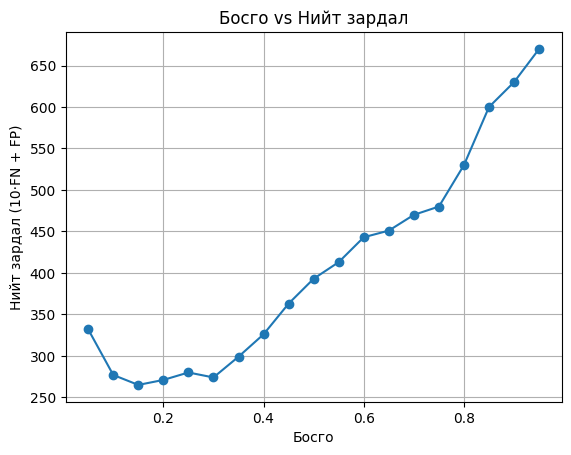

Хамгийн бага зардалтай босго: 0.15 зардал: 265
0.5 босгон дээрх зардал: 393


In [7]:
costs = []
for th in ths:
    tn, fp, fn, tp, *_ = metrics_at(th)
    costs.append(10 * fn + fp)

plt.plot(ths, costs, marker="o")
plt.xlabel("Босго"); plt.ylabel("Нийт зардал (10·FN + FP)")
plt.title("Босго vs Нийт зардал"); plt.grid(True)
plt.show()

best = ths[int(np.argmin(costs))]
print("Хамгийн бага зардалтай босго:", round(best, 2), "зардал:", min(costs))  # ≈ 0.15, ≈ 265

tn, fp, fn, tp, *_ = metrics_at(0.5)
print("0.5 босгон дээрх зардал:", 10 * fn + fp)   # 10*39 + 3 = 393

В4

**Үр дүн:** 0.05-аас 0.95 хүртэл 0.05 алхмаар шалгахад зардал хамгийн бага байх босго нь **0.15**, нийт зардал **265**.
0.5 босгон дээрх зардал **393**.

**0.5 босгон дээрх зардал хэд вэ:**
0.5 дээр FN = 39, FP = 3 тул зардал = 10·39 + 3 = 393. 0.15 дээр FN = 21, FP = 55 тул 10·21 + 55 = 265.
Зөрүү нь 393 − 265 = 128 нэгж, ойролцоогоор 33% бага.

**Яагаад 0.5 нь "зөв" босго биш вэ:**
0.5 босго нь "магадлал нь 50%-иас дээш бол default" гэсэн дүрэм бөгөөд алдаа бүрийг адил үнэтэй гэж үздэг.
Харин бодит байдалд алдсан default (FN) нь буруу дохиололоос (FP) 10 дахин үнэтэй. Иймд зарим хүнийг буруугаар
шалгах (FP нэмэгдэх) нь хямд, default-г алдах нь үнэтэй тул босгыг доош буулгах нь зөв.
Өөрөөр хэлбэл зөв босго нь загвар ганцаараа бус, **бизнесийн алдааны зардлаас** хамаарна.

**Графикаас:** босго буурахад FN буурч зардал эхэндээ буурдаг. Гэхдээ 0.15-аас цааш бага болговол FP хэт өсч
зардал дахин нэмэгдэнэ. Тиймээс муруй доод цэгтэй (минимумтай) байна.